# AICS-202 | Laboratory 04
## Defensive Retraining and Robustness Assessment
Course module: 4 | Suggested duration: 5 hours

**Objective:** compare a baseline model with a model trained using simple augmented adversarial samples. Independently evaluate both models with FGSM and a small PGD variant.

**Important:** augmentation is not a guarantee of robustness; attacks must be adapted to the defended model to avoid misleading results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

In [3]:
def pgd(model, features, labels, epsilon=0.12, alpha=0.03, steps=7, seed=42):
    rng = np.random.default_rng(seed)
    original = features.copy()
    perturbed = np.clip(original + rng.uniform(-epsilon, epsilon, size=original.shape), 0, 1)
    for _ in range(steps):
        grad = input_loss_gradient(model, perturbed, labels)
        perturbed = perturbed + alpha * np.sign(grad)
        perturbed = np.maximum(np.minimum(perturbed, original + epsilon), original - epsilon)
        perturbed = np.clip(perturbed, 0.0, 1.0)
    return perturbed

Baseline: clean=0.962 | FGSM=0.516 | PGD=0.489
Augmented training: clean=0.940 | FGSM=0.284 | PGD=0.260


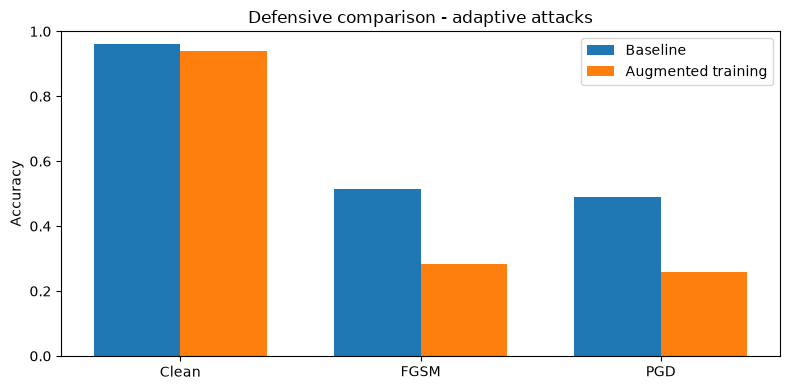

In [4]:
train_adversarial = fgsm(model, X_train, y_train, epsilon=0.10)
aug_features = np.concatenate([X_train, train_adversarial])
aug_labels = np.concatenate([y_train, y_train])
defended = build_model(aug_features, aug_labels)

def evaluate(model_to_test, label):
    clean = accuracy_score(y_test, model_to_test.predict(X_test))
    test_fgsm = fgsm(model_to_test, X_test, y_test, epsilon=0.12)
    test_pgd = pgd(model_to_test, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)
    fgsm_acc = accuracy_score(y_test, model_to_test.predict(test_fgsm))
    pgd_acc = accuracy_score(y_test, model_to_test.predict(test_pgd))
    print(f'{label}: clean={clean:.3f} | FGSM={fgsm_acc:.3f} | PGD={pgd_acc:.3f}')
    return [clean, fgsm_acc, pgd_acc]
base_results = evaluate(model, 'Baseline')
def_results = evaluate(defended, 'Augmented training')
ind = np.arange(3)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(ind-.18, base_results, width=.36, label='Baseline')
ax.bar(ind+.18, def_results, width=.36, label='Augmented training')
ax.set_xticks(ind, ['Clean', 'FGSM', 'PGD']); ax.set_ylim(0,1)
ax.set_ylabel('Accuracy'); ax.set_title('Defensive comparison - adaptive attacks')
ax.legend(); plt.tight_layout();plt.show()

### Final practical evidence and risk conclusion
1. Compare clean-test and attacked-test accuracy for both models.
2. Explain why defensive effectiveness must be tested against the defended model itself.
3. Identify three limitations of this small dataset and short attack budget.
4. Produce a one-page robustness decision memo: deploy, improve or reject, with a rationale.

**Deliverables:** comparison chart, numeric results, limitations and decision memo. This is a local learning exercise, not a certification of model security.

In [5]:
variant_results = {}
for aug_eps in [0.03, 0.05]:
    adv_train = fgsm(model, X_train, y_train, epsilon=aug_eps)
    variant_model = build_model(np.concatenate([X_train, adv_train]), np.concatenate([y_train, y_train]))
    variant_results[aug_eps] = evaluate(variant_model, f'Augmented, augmentation epsilon {aug_eps}')

print()
print("Variant | Clean | FGSM | PGD")
rows = [("Baseline", base_results), ("Augmented eps 0.10", def_results)]
rows += [(f"Augmented eps {e}", r) for e, r in variant_results.items()]
for name, r in rows:
    print(f"{name} | {r[0]:.3f} | {r[1]:.3f} | {r[2]:.3f}")

Augmented, augmentation epsilon 0.03: clean=0.962 | FGSM=0.467 | PGD=0.438
Augmented, augmentation epsilon 0.05: clean=0.958 | FGSM=0.433 | PGD=0.402

Variant | Clean | FGSM | PGD
Baseline | 0.962 | 0.516 | 0.489
Augmented eps 0.10 | 0.940 | 0.284 | 0.260
Augmented eps 0.03 | 0.962 | 0.467 | 0.438
Augmented eps 0.05 | 0.958 | 0.433 | 0.402


## Final practical evidence and risk conclusion

### 1. Clean and attacked accuracy for both models
| Variant | Clean | FGSM | PGD |
|---|---|---|---|
| Baseline | 0.962 | 0.516 | 0.489 |
| Augmented, augmentation epsilon 0.10 | 0.940 | 0.284 | 0.260 |
| Augmented, augmentation epsilon 0.05 | 0.958 | 0.433 | 0.402 |
| Augmented, augmentation epsilon 0.03 | 0.962 | 0.467 | 0.438 |

Every model was attacked with examples generated against that model, on the same 450 test images (E04_metrics_table, E04_comparison_chart, E04_improvement_variant).

### 2. Why the defended model itself must be tested
An attacker targets what is actually deployed. If I had tested the retrained model only with images crafted for the baseline, the result would have measured the wrong thing and could have made the defence look better than it is. Generating FGSM and PGD examples against each candidate gives a fairer comparison.

### 3. Limitations
* The dataset is tiny (8×8 images, 1,797 samples) and the model is a simple linear classifier.
* The attacks are white-box and short, with a limited number of steps, and I used one seed and one split.
* I tested one type of defence, simple FGSM augmentation, at three augmentation strengths. Other defences were not tested.

### 4. Decision memo
**To:** Technical review board (hypothetical)
**From:** Janet Anya Okewu-Ihezie
**Date:** 14 November 2026
**Decision:** Reject this mitigation as tested. Carry out further controlled testing of alternatives before any adoption.

**Evidence:** In my run, simple adversarial augmentation did not improve robustness at any setting. Under FGSM and PGD, accuracy fell by about 5 points at augmentation epsilon 0.03, 8 to 9 points at 0.05 and 23 points at 0.10, relative to the baseline. Clean accuracy was unchanged at 0.03 and fell by 2.2 points at 0.10.

**Improvements and regressions:** There was no robustness improvement. The regressions grew with the augmentation epsilon. Retraining also adds cost and complexity (a larger training set and more steps) without a measured benefit.

**Rationale:** Adopting a control that lowers measured robustness would make the system less safe while appearing more secure. The intention behind the defence does not change the measured result.

**Possible explanations (not tested):** limited capacity of a linear model, augmented images generated once from the baseline model, and a mismatch between augmentation and attack strength.

**Conditions to revisit:** repeat with several seeds, test other training mixtures and model types, and use a stronger or different adaptive attack set. Any new candidate must be tested against itself, on the same held-out data, before sign-off.

**Residual risk:** Black-box, targeted and physical-world attacks were not tested. This is a local learning exercise and not a certification of model security.

In [6]:
import inspect
print(inspect.getsource(evaluate))
print(inspect.getsource(pgd))

def evaluate(model_to_test, label):
    clean = accuracy_score(y_test, model_to_test.predict(X_test))
    test_fgsm = fgsm(model_to_test, X_test, y_test, epsilon=0.12)
    test_pgd = pgd(model_to_test, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)
    fgsm_acc = accuracy_score(y_test, model_to_test.predict(test_fgsm))
    pgd_acc = accuracy_score(y_test, model_to_test.predict(test_pgd))
    print(f'{label}: clean={clean:.3f} | FGSM={fgsm_acc:.3f} | PGD={pgd_acc:.3f}')
    return [clean, fgsm_acc, pgd_acc]

def pgd(model, features, labels, epsilon=0.12, alpha=0.03, steps=7, seed=42):
    rng = np.random.default_rng(seed)
    original = features.copy()
    perturbed = np.clip(original + rng.uniform(-epsilon, epsilon, size=original.shape), 0, 1)
    for _ in range(steps):
        grad = input_loss_gradient(model, perturbed, labels)
        perturbed = perturbed + alpha * np.sign(grad)
        perturbed = np.maximum(np.minimum(perturbed, original + epsilon), original - epsilon)
      